Calculate how recall transitions depend on item distance. Align a precomputed distance matrix with the studied items, choose distance bins and save the conditional response probabilities.

## Settings


In [1]:
#| code-summary: "1 — Set the parameters for this run"

# Working directory (None discovers the enclosing Git project).
project_root = None


# Response files
data_path = None  # A supplied single path takes precedence over data_paths.
data_paths = [
    "data/Dupertuys2026.h5",
    "data/simulations/Dupertuys2026_CMR_demo_best_of_3.h5",
    "data/simulations/Dupertuys2026_eCMR_source_only_demo_best_of_3.h5",
    "data/simulations/Dupertuys2026_eCMR_broad_demo_best_of_3.h5",
]
data_labels = ["Observed", "CMR", "Source-only eCMR", "Broader eCMR"]

# Saved results
output_dir = "results/distcrp"


# Analysis and uncertainty settings
confidence_level = 0.95
distance_matrix_path = "data/Dupertuys2026_semantic_distances.npy"
features_path = None  # Optional item features; overrides the distance matrix.
distance_path = None  # Accept the earlier preview name when supplied.
bin_percentiles = [25, 50, 75]
plot_seed = 0  # NumPy seed for bootstrap displays.

max_subjects = 0
figure_dir = None
figure_str = "distcrp"  # Empty displays the figure without saving it.


# Condition selection
trial_query = None
trial_queries = ["data['list_type'] == 1"]
labels = ["Mixed lists"]
selection_label = "Mixed lists"


# Figure appearance
color_cycle = None
ylim = None
yticks = None

complete_lists_only = False

contrast_name = None

bin_edges = None  # Interior boundaries, "min_count", or None for percentiles.
min_transitions_per_subject = 10
bin_step = 0.05
bin_source_index = 0  # Input used to set common min-count bins.


In [2]:
#| code-summary: "2 — Prepare the Colab environment"

import sys

if "google.colab" in sys.modules:
    import subprocess

    revision = "main"
    subprocess.check_call(
        [
            sys.executable,
            "-m",
            "pip",
            "install",
            "--upgrade",
            f"jaxcmr[colab] @ git+https://github.com/githubpsyche/jaxcmr.git@{revision}",
        ]
    )
    from jaxcmr.colab import fetch_inputs

    fetch_inputs(
        ([data_path] if data_path is not None else data_paths)
        + [features_path or distance_path or distance_matrix_path],
        revision=revision, base_dir=project_root,
    )


In [3]:
#| code-summary: "3 — Import packages"

import sys
from pathlib import Path

import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np
from tabulate import tabulate

from jaxcmr.analyses.distcrp import (
    compute_distance_bins_min_count,
    compute_distance_bins_percentiles,
    plot_dist_crp,
)
from jaxcmr.helpers import find_project_root, resolve_project_path, generate_trial_mask, load_data, save_figure
from jaxcmr.math import cosine_similarity_matrix


## Align items with the distance matrix


In [4]:
#| code-summary: "4 — Resolve input paths, conditions and output settings"

if project_root is not None:
    root_path = resolve_project_path(project_root, Path.cwd())
elif "google.colab" in sys.modules:
    root_path = Path.cwd()
else:
    try:
        root_path = Path(find_project_root())
    except FileNotFoundError:
        root_path = Path.cwd()
print("Project directory:", root_path)

np.random.seed(plot_seed)
output_dir = resolve_project_path(output_dir, root_path)
figure_dir = resolve_project_path(figure_dir, root_path) if figure_dir is not None else output_dir

queries = trial_queries if trial_query is None else [trial_query]
condition_labels = labels if trial_query is None else [selection_label]
input_paths = [data_path] if data_path is not None else data_paths
input_paths = [resolve_project_path(path, root_path) for path in input_paths]
input_labels = [selection_label] if data_path is not None else data_labels
if len(queries) != len(condition_labels) or len(input_paths) != len(input_labels):
    raise ValueError("Supply a label for each input and each condition query.")


In [5]:
#| code-summary: "5 — Load the supplied response datasets"

datasets = [load_data(str(path), max_subjects=max_subjects) for path in input_paths]


In [6]:
#| code-summary: "6 — Select observations and report participant counts"

masks_by_dataset = []
for dataset, dataset_label in zip(datasets, input_labels):
    condition_masks = [generate_trial_mask(dataset, query) for query in queries]
    if complete_lists_only:
        condition_masks = [
            condition_mask & jnp.all(dataset["pres_itemnos"] > 0, axis=1)
            for condition_mask in condition_masks
        ]
    masks_by_dataset.append(condition_masks)
    for condition_label, condition_mask in zip(condition_labels, condition_masks):
        participant_ids = np.unique(
            np.asarray(dataset["subject"]).ravel()[np.asarray(condition_mask)]
        )
        print(
            f"{dataset_label} / {condition_label}: {int(condition_mask.sum())} lists, {len(participant_ids)} participants"
        )
        if not len(participant_ids):
            raise ValueError(
                "The selected input and condition contain no eligible lists."
            )
data, trial_masks = datasets[0], masks_by_dataset[0]


Observed / Mixed lists: 246 lists, 123 participants
CMR / Mixed lists: 2460 lists, 123 participants
Source-only eCMR / Mixed lists: 2460 lists, 123 participants
Broader eCMR / Mixed lists: 2460 lists, 123 participants


In [7]:
#| code-summary: "7 — Load semantic distances or derive them from supplied features"

trial_mask = trial_masks[0]

if features_path:
    features = jnp.asarray(np.load(resolve_project_path(features_path, root_path)))
    distance_matrix = 1 - cosine_similarity_matrix(features)
else:
    distance_matrix = jnp.asarray(np.load(resolve_project_path(distance_path or distance_matrix_path, root_path)))


In [8]:
#| code-summary: "8 — Check item alignment and required within-list distances"

matrix = np.asarray(distance_matrix)
if matrix.ndim != 2 or matrix.shape[0] != matrix.shape[1]:
    raise ValueError("Supply a square distance matrix indexed by item ID minus one.")
for dataset, masks in zip(datasets, masks_by_dataset):
    for ids in np.asarray(dataset["pres_itemids"])[np.logical_or.reduce(masks)].astype(
        int
    ):
        ids = ids[ids > 0]
        distances = matrix[np.ix_(ids - 1, ids - 1)]
        if not np.isfinite(distances[~np.eye(len(ids), dtype=bool)]).all():
            raise ValueError("Some within-list alternatives have missing distances.")


In [9]:
#| code-summary: "9 — Inspect distances for selected item identities"

row = int(np.flatnonzero(np.asarray(trial_mask))[0])
item_ids = np.asarray(data["pres_itemids"])[row].astype(int)
item_ids = item_ids[item_ids > 0][:5]
print(
    tabulate(
        np.column_stack([item_ids, matrix[np.ix_(item_ids - 1, item_ids - 1)]]),
        headers=["Item ID", *item_ids],
        floatfmt=".3f",
    )
)


  Item ID       32       66     48       60       25
---------  -------  -------  -----  -------  -------
   32.000  nan        0.345  0.587    0.588    0.598
   66.000    0.345  nan      0.623    0.440    0.549
   48.000    0.587    0.623  0.000    0.662    0.561
   60.000    0.588    0.440  0.662  nan        0.575
   25.000    0.598    0.549  0.561    0.575  nan


## Choose shared bins and plot


In [10]:
#| code-summary: "10 — Calculate common distance bins for all response datasets"

if bin_edges is None or (isinstance(bin_edges, str) and bin_edges == "percentile"):
    edges, centers = compute_distance_bins_percentiles(
        distance_matrix, jnp.asarray(bin_percentiles)
    )
elif isinstance(bin_edges, str) and bin_edges == "min_count":
    edges, centers = compute_distance_bins_min_count(
        datasets[bin_source_index],
        distance_matrix,
        min_transitions_per_subject,
        step=bin_step,
        trial_mask=jnp.any(jnp.stack(masks_by_dataset[bin_source_index]), axis=0),
    )
else:
    edges, centers = jnp.asarray(bin_edges), None
print("Shared distance boundaries:", np.asarray(edges))


Shared distance boundaries: [0.45812285 0.57310474 0.6419725 ]


In [11]:
#| code-summary: "11 — Prepare the condition and dataset comparison panels"

panels = []
if data_path is not None:
    panels.append(
        {
            "datasets": [data] * len(queries),
            "trial_masks": trial_masks,
            "labels": condition_labels,
            "title": selection_label,
        }
    )
else:
    for condition_index, condition_label in enumerate(condition_labels):
        panels.append(
            {
                "datasets": datasets,
                "trial_masks": [masks[condition_index] for masks in masks_by_dataset],
                "labels": input_labels,
                "title": condition_label,
            }
        )


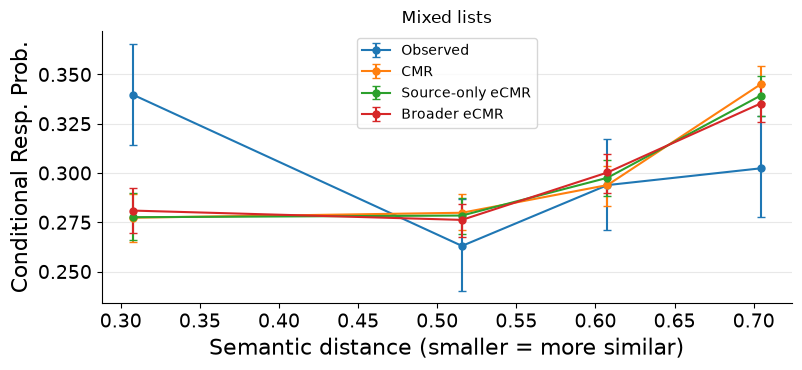

In [12]:
#| code-summary: "12 — Calculate, plot and save the selected comparison"

fig, axes = plt.subplots(len(panels), 1, figsize=(8, 3.8 * len(panels)), squeeze=False)
for ax, panel in zip(axes.ravel(), panels):
    panel_data = panel["datasets"]
    panel_masks = panel["trial_masks"]
    curve_labels = panel["labels"]
    title = panel["title"]
    plot_dist_crp(
        panel_data,
        panel_masks,
        distance_matrix=distance_matrix,
        bin_edges=edges,
        bin_centers=centers,
        labels=curve_labels,
        contrast_name=contrast_name,
        color_cycle=color_cycle,
        confidence_level=confidence_level,
        axis=ax,
    )
    ax.set_xlabel("Semantic distance (smaller = more similar)")
    ax.set_title(title)

    if ax.get_legend_handles_labels()[1]:
        ax.legend(title=contrast_name)
    if ylim is not None:
        ax.set_ylim(ylim)
    if yticks is not None:
        ax.set_yticks(yticks)
save_figure(str(figure_dir), figure_str)
